# Load Data

In [10]:
import pandas as pd
from pathlib import Path

RAW = Path("../datasheet/raw/oulad")

files = ["assessments", "courses", "studentAssessment", "studentInfo", "studentRegistration", "vle"]
df = {name: pd.read_csv(RAW / f"{name}.csv") for name in files}

for name, d in df.items():
    print(f"\n=== {name} | {d.shape[0]:,} baris x {d.shape[1]} kolom")
    na = d.isna().sum()
    na = na[na > 0]
    print(na.to_string() if len(na) else "tidak ada missing value")


=== assessments | 206 baris x 6 kolom
date    11

=== courses | 22 baris x 3 kolom
tidak ada missing value

=== studentAssessment | 173,912 baris x 5 kolom
score    173

=== studentInfo | 32,593 baris x 12 kolom
imd_band    1111

=== studentRegistration | 32,593 baris x 5 kolom
date_registration         45
date_unregistration    22521

=== vle | 6,364 baris x 6 kolom
week_from    5243
week_to      5243


In [11]:
asm = df["assessments"]
sa = df["studentAssessment"]

print("=== Jenis assessment:")
print(asm["assessment_type"].value_counts(), "\n")

print("=== Assessment yang date-nya kosong:")
print(asm[asm["date"].isna()]["assessment_type"].value_counts(), "\n")

print("=== Contoh isi studentAssessment:")
print(sa.head(), "\n")

print("=== is_banked:")
print(sa["is_banked"].value_counts())

=== Jenis assessment:
assessment_type
TMA     106
CMA      76
Exam     24
Name: count, dtype: int64 

=== Assessment yang date-nya kosong:
assessment_type
Exam    11
Name: count, dtype: int64 

=== Contoh isi studentAssessment:
   id_assessment  id_student  date_submitted  is_banked  score
0           1752       11391              18          0   78.0
1           1752       28400              22          0   70.0
2           1752       31604              17          0   72.0
3           1752       32885              26          0   69.0
4           1752       38053              19          0   79.0 

=== is_banked:
is_banked
0    172003
1      1909
Name: count, dtype: int64


## Cleaning 1: Buang baris banked
Baris `is_banked = 1` adalah nilai yang dibawa dari periode sebelumnya
(mahasiswa mengulang), bukan tugas yang benar-benar dikerjakan.

In [12]:
sa_clean = sa[sa["is_banked"] == 0]
print(len(sa), "→", len(sa_clean))

173912 → 172003


In [13]:
data = sa_clean.merge(asm, on="id_assessment", how="left")

print(data.shape)
print(data["assessment_type"].value_counts())
data.head()

(172003, 10)
assessment_type
TMA     97088
CMA     69956
Exam     4959
Name: count, dtype: int64


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


## Cleaning 2: Buang Exam + cek kualitas data
Exam dijadwalkan pada hari yang sama untuk semua mahasiswa,
jadi tidak mencerminkan durasi pengerjaan tugas.

In [14]:
# 1. Buang Exam
data = data[data["assessment_type"] != "Exam"]
print("Jumlah baris:", len(data))
print(data["assessment_type"].value_counts(), "\n")

# 2. Cek: masih ada deadline kosong?
print("Deadline kosong:", data["date"].isna().sum())

# 3. Cek: ada data dobel?
dobel = data.duplicated(subset=["id_student", "id_assessment"]).sum()
print("Baris dobel:", dobel, "\n")

# 4. Hitung selisih hari: deadline - tanggal kumpul
data["hari_sebelum_deadline"] = data["date"] - data["date_submitted"]
data["hari_sebelum_deadline"].describe()

Jumlah baris: 167044
assessment_type
TMA    97088
CMA    69956
Name: count, dtype: int64 

Deadline kosong: 0
Baris dobel: 0 



count    167044.000000
mean         15.885318
std          45.236433
min        -372.000000
25%          -2.000000
50%           1.000000
75%           5.000000
max         246.000000
Name: hari_sebelum_deadline, dtype: float64

## Bagian B · SiP Dataset

**Dataset:** SiP Task Effort Estimation (Software in Partnership Ltd, 2004–2014)
**Sumber:** https://github.com/Derek-Jones/SiP_dataset
**Lisensi:** CC BY-NC-ND 4.0 (data tidak boleh disebarkan ulang, termasuk hasil cleaning)
**Lokasi lokal:** `datasheet/raw/sip/`

In [15]:
SIP = Path("../datasheet/raw/sip")

sip = pd.read_csv(SIP / "Sip-task-info.csv", encoding="latin-1")
sip_dates = pd.read_csv(SIP / "est-act-dates.csv", encoding="latin-1")

for name, d in {"sip": sip, "sip_dates": sip_dates}.items():
    print(f"\n=== {name} | {d.shape[0]:,} baris x {d.shape[1]} kolom")
    na = d.isna().sum()
    na = na[na > 0]
    print(na.to_string() if len(na) else "tidak ada missing value")

sip.head()


=== sip | 12,299 baris x 17 kolom
AuthorisedByID          8034
DeveloperPerformance    2099

=== sip_dates | 12,299 baris x 4 kolom
StartedOn       353
CompletedOn    2586


,TaskNumber,Summary,Priority,RaisedByID,AssignedToID,AuthorisedByID,StatusCode,ProjectCode,ProjectBreakdownCode,Category,SubCategory,HoursEstimate,HoursActual,DeveloperID,DeveloperHoursActual,TaskPerformance,DeveloperPerformance
0,1735,Flag RI on SCM Message Summary screen using me...,1,58,58,6.0,FINISHED,PC2,PBC42,Development,Enhancement,14.0,1.75,58,1.75,12.25,12.25
1,1742,Allow RI Policies to be marked as Exhausted,1,58,42,6.0,FINISHED,PC2,PBC21,Development,Enhancement,7.0,7.00,42,7.00,0.00,0.00
2,1971,Fix Invalid UWREF Line DX402L99A1N,2,7,58,6.0,FINISHED,PC2,PBC75,Operational,In House Support,0.7,0.70,58,0.70,0.00,0.00
3,2134,New rows in the diary event for the SCM are re...,5,50,42,6.0,FINISHED,PC2,PBC42,Development,Bug,0.7,0.70,42,0.70,0.00,0.00
4,2251,Application Screen Size - Need to set Min Size...,10,46,13,6.0,FINISHED,PC2,PBC21,Development,Bug,3.5,3.50,13,3.50,0.00,0.00


In [16]:
print("=== Status tugas:")
print(sip["StatusCode"].value_counts(), "\n")

print("=== Bukti TaskPerformance = HoursEstimate - HoursActual:")
selisih = (sip["HoursEstimate"] - sip["HoursActual"] - sip["TaskPerformance"]).abs()
print("Jumlah baris yang TIDAK cocok:", (selisih > 0.01).sum(), "\n")

print("=== Tugas yang muncul lebih dari sekali:")
dobel = sip["TaskNumber"].value_counts()
print("Jumlah tugas dobel:", (dobel > 1).sum())
sip[sip["TaskNumber"] == dobel.index[0]][["TaskNumber", "DeveloperID", "HoursActual", "DeveloperHoursActual"]]

=== Status tugas:
StatusCode
FINISHED     4950
COMPLETED    4453
CHRONICLE    2323
RELEASED      288
CANCELLED     190
ESTIMATED      86
TEMPLATE        7
AUTHORISE       2
Name: count, dtype: int64 

=== Bukti TaskPerformance = HoursEstimate - HoursActual:
Jumlah baris yang TIDAK cocok: 0 

=== Tugas yang muncul lebih dari sekali:
Jumlah tugas dobel: 1384


,TaskNumber,DeveloperID,HoursActual,DeveloperHoursActual
3762,6889,13,8.0,1.0
3763,6889,24,8.0,1.0
3764,6889,26,8.0,1.0
3765,6889,42,8.0,1.0
3766,6889,43,8.0,1.0
3767,6889,54,8.0,1.0
3768,6889,58,8.0,1.0
3769,6889,65,8.0,1.0


### Cleaning SiP
1. Hanya tugas yang selesai (FINISHED, COMPLETED, RELEASED)
2. Buang kolom leakage (TaskPerformance, DeveloperPerformance) dan kolom administrasi (AuthorisedByID)
3. Hanya tugas yang dikerjakan 1 orang, supaya sesuai dengan pengguna PandAI (individu)

In [17]:
# Cleaning SiP 1: hanya tugas yang benar-benar selesai
selesai = ["FINISHED", "COMPLETED", "RELEASED"]
sip_clean = sip[sip["StatusCode"].isin(selesai)]
print("Setelah filter status :", len(sip_clean))

# Cleaning SiP 2: buang kolom leakage & administrasi
sip_clean = sip_clean.drop(columns=["TaskPerformance", "DeveloperPerformance", "AuthorisedByID"])

# Cleaning SiP 3: hanya tugas yang dikerjakan 1 orang
jumlah_orang = sip_clean.groupby("TaskNumber")["DeveloperID"].transform("size")
sip_clean = sip_clean[jumlah_orang == 1]
print("Setelah filter 1 orang:", len(sip_clean))
print("Total:", len(sip), "→", len(sip_clean))

Setelah filter status : 9691
Setelah filter 1 orang: 7176
Total: 12299 → 7176


In [20]:
pd.set_option("display.max_colwidth", 80)

cepat = sip_clean[sip_clean["HoursActual"] < 0.1]
cepat[["TaskNumber", "Summary", "SubCategory", "HoursEstimate", "HoursActual"]].sort_values("HoursActual")

,TaskNumber,Summary,SubCategory,HoursEstimate,HoursActual
486,3473,XXXX User Licencing not working (User YYY ZZZ and YYY ZZZ),In House Support,0.50,0.01
6582,9506,Risk Status Flow Needs Defining,Business Specification,0.01,0.01
1963,5053,MOA Change values in Drop Down Box,Enhancement,0.50,0.05
605,3627,Task System Licence,In House Support,0.05,0.05
1967,5057,Remove FIL code from Section,Enhancement,0.50,0.05
1965,5055,Remove Loss Basis from Section,Enhancement,0.50,0.05
1968,5058,"Trustfund on Section, just show code with ToolTip hover",Enhancement,1.00,0.05
1964,5054,Rename Area to Domicile in Section,Enhancement,0.50,0.05
1972,5062,Premium Line % and Written Line % on Line not used,Enhancement,1.00,0.05
1969,5059,"Limit and Excess, provide tooltip for column #",Enhancement,0.50,0.05


### Cek outlier durasi SiP

count    7176.00
mean        5.08
std        12.43
min         0.01
25%         0.75
50%         2.00
75%         4.25
max       339.90
Name: HoursActual, dtype: float64

Batas atas IQR : 9.5 jam → dibuang: 786
Batas domain 40 jam      → dibuang: 126
Kurang dari 6 menit       : 13


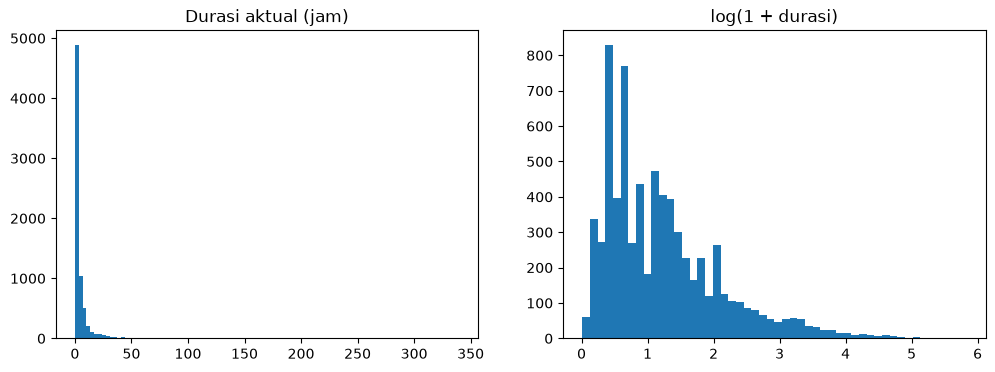

In [21]:
import numpy as np
import matplotlib.pyplot as plt

jam = sip_clean["HoursActual"]
print(jam.describe().round(2))

q1, q3 = jam.quantile([0.25, 0.75])
batas_iqr = q3 + 1.5 * (q3 - q1)
print("\nBatas atas IQR :", batas_iqr, "jam → dibuang:", (jam > batas_iqr).sum())
print("Batas domain 40 jam      → dibuang:", (jam > 40).sum())
print("Kurang dari 6 menit       :", (jam < 0.1).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(jam, bins=100)
ax[0].set_title("Durasi aktual (jam)")
ax[1].hist(np.log1p(jam), bins=50)
ax[1].set_title("log(1 + durasi)")
plt.show()

In [ ]:
# 0.1 = 6 menit (batas bawah) <==> 40 jam (batas atas)
sip_clean = sip_clean[(sip_clean["HoursActual"] >= 0.1) & (sip_clean["HoursActual"] <= 40)]
print(len(sip_clean))   # → 7037

7037
